---

## #11. 지도학습 베이스라인
#### 베이스라인 구축

> 베이스라인은 하이퍼파라미터 튜닝 없이 기본 설정만으로 학습한 모델로서, 하이퍼파라미터 튜닝 결과가 최소 이정도는 나와야 한다는 기준선 역할을 수행한다.

| 모델군 | 모델 | 전처리 |
|---|---|---|
| 선형 4종 | LogisticRegression, RidgeClassifier,<br>Lasso(L1 로지스틱), ElasticNet(SGD) | `vif=True, scale=True, drop_first=True` |
| 비선형 2종 | KNN · SVC(probability=True) | `vif=True, scale=True, drop_first=True` |
| 트리 1종 | DecisionTree | `vif=True, encode=True` (전 범주 유지) |
| 앙상블 4종 | RandomForest · XGBoost · LightGBM | `vif=True, encode=True` |
| 앙상블 4종 | CatBoost | `encode=False` + `cat_features` 직접 전달 |

---
### 11-1. 베이스라인 구축 준비작업
#### (1) 이전 단계(`Titanic_LogisticRegression` - **#10**)에서 저장한 파일 불러오기

In [1]:
import json
import pandas as pd

# '#10. 최종 변수 선택'까지 완료된 데이터셋 불러오기
df = pd.read_pickle("titanic/data/titanic_df.pkl")

with open("titanic/data/column_means.json", encoding="utf-8") as f:
    column_means = json.load(f)

print(df.shape)
display(df.dtypes)

(891, 7)


Survived      category
Pclass        category
Age            float64
Fare           float64
Embarked      category
FamilySize       int64
Title         category
dtype: object

#### (2) 지도학습을 위한 라이브러리 참조

In [2]:
import sys
sys.path.append("D:\\")
from helpers import *
from IPython.display import display, Markdown

import pandas as pd
import numpy as np

import datetime as dt
import os
import glob as gl   # 파일 목록을 리스트로 반환하는 파이썬 내장 모듈

# 훈련,검증 데이터 분리 함수
from sklearn.model_selection import train_test_split

# 하이퍼파라미터 튜닝
from sklearn.model_selection import GridSearchCV

# 선형 계열 모델
from sklearn.linear_model import LogisticRegression, RidgeClassifier, SGDClassifier

# 비선형 계열 모델
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

# 트리계열 모델
from sklearn.tree import DecisionTreeClassifier

# 앙상블 모델
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

#### (3) 데이터 분할 — 훈련/검증용

In [3]:
# 독립변수 분리
feature = df.drop(columns=['Survived'])

# 종속변수 분리
target = df['Survived']

# 훈련, 검증 데이터 분할
# → 분류 문제이므로 `stratify=target` 을 지정해 불균형 문제를 해결한다.
x_train, x_test, y_train, y_test = train_test_split(
    feature, target, test_size=0.2, random_state=RANDOM_STATE, stratify=target) 
                                                               # stratify=target : 종속변수의 범주 비율 유지

x_train.shape, x_test.shape, y_train.shape, y_test.shape

((712, 6), (179, 6), (712,), (179,))

#### (4) 학습을 완료한 모델이 저장될 폴더

In [4]:
baseline_dir = f"titanic/baseline"  # 베이스라인 모델이 저장될 경로

if not os.path.exists(baseline_dir):
    os.makedirs(baseline_dir)

#### 💡 인사이트

| 항목 | 값 |
|---|---|
| 분석 데이터 | 891행 × 7열 (종속변수 1개 + 독립변수 6개) |
| 훈련 / 검증 분할 | **712행 / 179행** (8 : 2, `stratify=target`) |
| 독립변수 | 명목형 3개(`Pclass`, `Embarked`, `Title`) · 연속형 3개(`Age`, `Fare`, `FamilySize`) |

- **#10의 변수 선택이 그대로 반영됐다.** 01 노트북에서 제외하기로 한 `Sex`(`Title`과 V = 0.998 중복), `SibSp`·`Parch`(`FamilySize`와 VIF = ∞ 중복)를 뺀 데이터를 불러왔으므로, 투입 변수 6개 사이에 구조적 중복이 없다.
  - 명목형 3개는 더미 변수 8개(`Pclass` 2 + `Embarked` 2 + `Title` 4, `drop_first=True` 기준)가 되어, 연속형 3개와 합쳐 모델 입력은 최대 11개 컬럼이다.
  - #10에서 "투입 후 판정"으로 보류한 `Age`·`Embarked`는 제외하지 않고 포함했다.
- **검증 데이터가 179명뿐이라 1명의 차이가 지표를 눈에 띄게 움직인다.**
  - 이후 모든 재현율 값이 분모 69의 분수(예: 0.725 = 50/69)로 떨어지므로, **검증 데이터의 생존자는 69명, 사망자는 110명**임을 알 수 있다.
  - 즉 **1명 = 정확도 약 0.56%p, 재현율 약 1.4%p**다. 이어지는 모델 간 순위 차이는 "몇 명 차이"일 수 있다는 점을 염두에 두고 읽어야 한다.
- `stratify=target`으로 훈련·검증 모두 생존 비율(약 38%)이 유지되어, 정확도의 바닥값(전원 사망 예측 61.6%)을 두 데이터에 같은 기준으로 적용할 수 있다.
- ⚠️ **#10-3에서 예고한 변수 변환(`Fare` log1p, `FamilySize` 구간화, `Age` 어린이 더미)은 적용하지 않았다.** 이 노트북의 결과는 세 변수의 원래 값 기준이다. 트리 계열은 영향이 작지만, 선형·거리 기반 모델은 변환 여부에 따라 달라질 수 있다.

### 11-2. 선형 계열 모델(1) — LogisticRegression

In [5]:
# 학습 모델 객체 생성
model = LogisticRegression(random_state=RANDOM_STATE)

# 모델이름 문자열 구성 (클래스 이름을 소문자 변환 후 "regression" 꼬리 제거)
model_name = model.__class__.__name__.lower().removesuffix("regression")

# 파이프라인 구축 -> 학습 -> 저장
model = my_ml.fit_pipeline(
                model=model,                              # 학습 모델
                x_train=x_train, y_train=y_train,         # 훈련 데이터 (독립,종속)
                vif=True,                                 # 다중공선성 확인 여부
                scale=True,                               # 기본값이 L2 규제이므로 스케일링 필요
                drop_first=True,                          # 더미변수 생성(첫번째 컬럼 제거)
                save_path=f"{baseline_dir}/{model_name}.pkl")  # 모델 저장 경로

display(my_ml.cls_score(model, x_test, y_test))           # 모델 성능평가
display(model)                                            # 모델 구조 출력

대상: 712행 x 6열 | 모델: logistic
명목형: ['Pclass', 'Embarked', 'Title']
연속형: ['Age', 'Fare', 'FamilySize']

전처리 단계
  연속형: 다중공선성 제거(VIF >= 10.0) → 정규화(standard)
  명목형: 더미변수 인코딩(drop_first=True)

모델 학습 완료: logistic
모델 저장: titanic/baseline/logistic.pkl


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,DOR
Model,,,,,,,
LogisticRegression,0.787709,0.754098,0.666667,0.707692,0.83386,0.823978,12.666667


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['Pclass','Age','Fare','Embarked','FamilySize','Title']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
name_,str,'lo...ic'
pipeline_info_,dict,"{'ca...te': 'mo...nt', 'co...ls': ['Age', 'Fare', 'Fa...ze'], 'dr...st': True, 'encode': True, ...}"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"


### 11-3. 선형 계열 모델(2) — RidgeClassifier

In [6]:
# 학습 모델 객체 생성
model = RidgeClassifier(random_state=RANDOM_STATE)

# 모델이름 문자열 구성 (클래스 이름을 소문자 변환 후 "classifier" 꼬리 제거)
model_name = model.__class__.__name__.lower().removesuffix("classifier")

# 파이프라인 구축 -> 학습 -> 저장
model = my_ml.fit_pipeline(
                model=model,                              # 학습 모델
                x_train=x_train, y_train=y_train,         # 훈련 데이터 (독립,종속)
                vif=True,                                 # 다중공선성 확인 여부
                scale=True,                               # 계수에 벌점을 매기므로 스케일링 필요
                drop_first=True,                          # 더미변수 생성(첫번째 컬럼 제거)
                save_path=f"{baseline_dir}/{model_name}.pkl")  # 모델 저장 경로

display(my_ml.cls_score(model, x_test, y_test))           # 모델 성능평가
display(model)                                            # 모델 구조 출력

대상: 712행 x 6열 | 모델: ridge
명목형: ['Pclass', 'Embarked', 'Title']
연속형: ['Age', 'Fare', 'FamilySize']

전처리 단계
  연속형: 다중공선성 제거(VIF >= 10.0) → 정규화(standard)
  명목형: 더미변수 인코딩(drop_first=True)

모델 학습 완료: ridge
모델 저장: titanic/baseline/ridge.pkl


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,DOR
Model,,,,,,,
RidgeClassifier,0.804469,0.774194,0.695652,0.732824,0.831489,0.822862,15.673469


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['Pclass','Age','Fare','Embarked','FamilySize','Title']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
name_,str,'ridge'
pipeline_info_,dict,"{'ca...te': 'mo...nt', 'co...ls': ['Age', 'Fare', 'Fa...ze'], 'dr...st': True, 'encode': True, ...}"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"


### 11-4. 선형 계열 모델(3) — Lasso

In [7]:
# 학습 모델 객체 생성
# 분류에는 Lasso 클래스가 없다. L1 규제를 건 로지스틱 회귀가 그 자리를 대신한다.
model = LogisticRegression(l1_ratio=1, solver="liblinear", random_state=RANDOM_STATE)

# 모델이름 문자열 구성 (1번 모델과 클래스가 같아 이름이 겹치므로 직접 지정)
model_name = "lasso"

# 파이프라인 구축 -> 학습 -> 저장
model = my_ml.fit_pipeline(
                model=model,                              # 학습 모델
                x_train=x_train, y_train=y_train,         # 훈련 데이터 (독립,종속)
                vif=True,                                 # 다중공선성 확인 여부
                scale=True,                               # 계수에 벌점을 매기므로 스케일링 필요
                drop_first=True,                          # 더미변수 생성(첫번째 컬럼 제거)
                name=model_name,                          # 모델을 구분할 이름
                save_path=f"{baseline_dir}/{model_name}.pkl")  # 모델 저장 경로

display(my_ml.cls_score(model, x_test, y_test))           # 모델 성능평가
display(model)                                            # 모델 구조 출력

대상: 712행 x 6열 | 모델: lasso
명목형: ['Pclass', 'Embarked', 'Title']
연속형: ['Age', 'Fare', 'FamilySize']

전처리 단계
  연속형: 다중공선성 제거(VIF >= 10.0) → 정규화(standard)
  명목형: 더미변수 인코딩(drop_first=True)

모델 학습 완료: lasso
모델 저장: titanic/baseline/lasso.pkl


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,DOR
Model,,,,,,,
LogisticRegression,0.815642,0.78125,0.724638,0.75188,0.833729,0.82745,18.045113


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['Pclass','Age','Fare','Embarked','FamilySize','Title']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
name_,str,'lasso'
pipeline_info_,dict,"{'ca...te': 'mo...nt', 'co...ls': ['Age', 'Fare', 'Fa...ze'], 'dr...st': True, 'encode': True, ...}"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"


### 11-5. 선형 계열 모델(4) — ElasticNet

In [8]:
# 학습 모델 객체 생성
# loss="log_loss" 는 로지스틱 회귀와 같은 확률 모형, penalty="elasticnet" 은 L1+L2 규제
model = SGDClassifier(loss="log_loss", penalty="elasticnet",
                      random_state=RANDOM_STATE, n_jobs=-1)

# 모델이름 문자열 구성 (클래스명(sgd)이 아니라 규제 방식으로 부르기 위해 직접 지정)
model_name = "elasticnet"

# 파이프라인 구축 -> 학습 -> 저장
model = my_ml.fit_pipeline(
                model=model,                              # 학습 모델
                x_train=x_train, y_train=y_train,         # 훈련 데이터 (독립,종속)
                vif=True,                                 # 다중공선성 확인 여부
                scale=True,                               # 계수에 벌점을 매기므로 스케일링 필요
                drop_first=True,                          # 더미변수 생성(첫번째 컬럼 제거)
                name=model_name,                          # 모델을 구분할 이름
                save_path=f"{baseline_dir}/{model_name}.pkl")  # 모델 저장 경로

display(my_ml.cls_score(model, x_test, y_test))           # 모델 성능평가
display(model)                                            # 모델 구조 출력

대상: 712행 x 6열 | 모델: elasticnet
명목형: ['Pclass', 'Embarked', 'Title']
연속형: ['Age', 'Fare', 'FamilySize']

전처리 단계
  연속형: 다중공선성 제거(VIF >= 10.0) → 정규화(standard)
  명목형: 더미변수 인코딩(drop_first=True)

모델 학습 완료: elasticnet
모델 저장: titanic/baseline/elasticnet.pkl


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,DOR
Model,,,,,,,
SGDClassifier,0.776536,0.710145,0.710145,0.710145,0.821344,0.81273,11.025


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['Pclass','Age','Fare','Embarked','FamilySize','Title']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
name_,str,'el...et'
pipeline_info_,dict,"{'ca...te': 'mo...nt', 'co...ls': ['Age', 'Fare', 'Fa...ze'], 'dr...st': True, 'encode': True, ...}"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"


#### 💡 인사이트 (선형 계열 4종)

| 모델 | Accuracy | Precision | Recall | F1 | ROC_AUC |
|---|---|---|---|---|---|
| `LogisticRegression` | 0.788 | 0.754 | 0.667 | 0.708 | **0.834** |
| `RidgeClassifier` | 0.804 | 0.774 | 0.696 | 0.733 | 0.831 |
| `Lasso (L1 로지스틱)` | **0.816** | **0.781** | **0.725** | **0.752** | 0.834 |
| `ElasticNet (SGD)` | 0.777 | 0.710 | 0.710 | 0.710 | 0.821 |

- **Lasso(L1 로지스틱)가 4종 중 1위**다. F1 0.752, Accuracy 0.816로, 규제만 L2(기본)인 `LogisticRegression`(F1 0.708, Accuracy 0.788)보다 F1이 **0.044**, 정확도가 **2.8%p(5명)** 높다.
  - 모형 구조는 같고 **규제 방식(L1 ↔ L2)만 다른데 결과가 갈렸다.** 투입 변수 6개 사이에 구조적 중복이 없는데도 차이가 나므로, 중복 변수 때문이라고 볼 수는 없다. 어떤 계수가 0이 됐는지는 아직 확인하지 않았으므로 원인은 계수·SHAP 단계에서 확인한다.
- **`RidgeClassifier`도 F1 0.733로 기본 로지스틱(0.708)보다 높다.**
- **`ElasticNet`(SGD)은 Accuracy 0.777, ROC_AUC 0.821로 4종 중 가장 낮다.** 정밀도와 재현율이 0.710로 같아, 이전의 다른 선형 모델처럼 생존자를 놓치는 쪽으로 기울지는 않았다.
- **선형 4종의 ROC_AUC는 0.821~0.834** 로 좁은 범위인데 F1은 0.708~0.752로 벌어진다. 순위 예측력은 비슷하고 분류 기준값(0.5) 근처의 소수 승객에서 차이가 난다.

### 11-6. 비선형 계열 모델(1) — KNN

In [9]:
# 학습 모델 객체 생성
model = KNeighborsClassifier(n_jobs=-1)

# 모델이름 문자열 구성 (클래스 이름을 소문자 변환 후 "classifier" 꼬리 제거)
model_name = model.__class__.__name__.lower().removesuffix("classifier")

# 파이프라인 구축 -> 학습 -> 저장
model = my_ml.fit_pipeline(
                model=model,                              # 학습 모델
                x_train=x_train, y_train=y_train,         # 훈련 데이터 (독립,종속)
                vif=True,                                 # 다중공선성 확인 여부
                scale=True,                               # 거리로 학습하므로 스케일링 필요
                drop_first=True,                          # 더미변수 생성(첫번째 컬럼 제거)
                save_path=f"{baseline_dir}/{model_name}.pkl")  # 모델 저장 경로

display(my_ml.cls_score(model, x_test, y_test))           # 모델 성능평가
display(model)                                            # 모델 구조 출력

대상: 712행 x 6열 | 모델: kneighbors
명목형: ['Pclass', 'Embarked', 'Title']
연속형: ['Age', 'Fare', 'FamilySize']

전처리 단계
  연속형: 다중공선성 제거(VIF >= 10.0) → 정규화(standard)
  명목형: 더미변수 인코딩(drop_first=True)

모델 학습 완료: kneighbors
모델 저장: titanic/baseline/kneighbors.pkl


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,DOR
Model,,,,,,,
KNeighborsClassifier,0.843575,0.825397,0.753623,0.787879,0.865349,0.80421,27.529412


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['Pclass','Age','Fare','Embarked','FamilySize','Title']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
name_,str,'kn...rs'
pipeline_info_,dict,"{'ca...te': 'mo...nt', 'co...ls': ['Age', 'Fare', 'Fa...ze'], 'dr...st': True, 'encode': True, ...}"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"


### 11-7. 비선형 계열 모델(2) — Support Vector Classifier

In [10]:
# 학습 모델 객체 생성
# probability=True 로 두어야 확률 기반 지표(LogLoss)까지 계산된다.
# 확률을 얻으려고 내부에서 교차검증을 한 번 더 돌리므로 그만큼 느려진다.
model = SVC(probability=True, random_state=RANDOM_STATE)

# 모델이름 문자열 구성 (클래스 이름을 소문자 변환 후 "classifier" 꼬리 제거)
model_name = model.__class__.__name__.lower().removesuffix("classifier")

# 파이프라인 구축 -> 학습 -> 저장
model = my_ml.fit_pipeline(
                model=model,                              # 학습 모델
                x_train=x_train, y_train=y_train,         # 훈련 데이터 (독립,종속)
                vif=True,                                 # 다중공선성 확인 여부
                scale=True,                               # 마진으로 학습하므로 스케일링 필요
                drop_first=True,                          # 더미변수 생성(첫번째 컬럼 제거)
                save_path=f"{baseline_dir}/{model_name}.pkl")  # 모델 저장 경로

display(my_ml.cls_score(model, x_test, y_test))           # 모델 성능평가
display(model)                                            # 모델 구조 출력

대상: 712행 x 6열 | 모델: svc
명목형: ['Pclass', 'Embarked', 'Title']
연속형: ['Age', 'Fare', 'FamilySize']

전처리 단계
  연속형: 다중공선성 제거(VIF >= 10.0) → 정규화(standard)
  명목형: 더미변수 인코딩(drop_first=True)

모델 학습 완료: svc
모델 저장: titanic/baseline/svc.pkl


c:\Users\bhc\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,DOR
Model,,,,,,,
SVC,0.810056,0.777778,0.710145,0.742424,0.832016,0.826443,16.8


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['Pclass','Age','Fare','Embarked','FamilySize','Title']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
name_,str,'svc'
pipeline_info_,dict,"{'ca...te': 'mo...nt', 'co...ls': ['Age', 'Fare', 'Fa...ze'], 'dr...st': True, 'encode': True, ...}"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"


#### 💡 인사이트 (비선형 계열 2종)

| 모델 | Accuracy | Precision | Recall | F1 | ROC_AUC |
|---|---|---|---|---|---|
| `KNN` | **0.844** | **0.825** | **0.754** | **0.788** | **0.865** |
| `SVC` | 0.810 | 0.778 | 0.710 | 0.742 | 0.832 |

- **KNN은 기본값(이웃 5명)만으로 11개 모델 중 F1(0.788)·Accuracy(0.844)·ROC_AUC(0.865)·정밀도·DOR 모두 1위**다.
  - 2위 Lasso와 비교하면 생존자를 52명 맞혀(Lasso 50명) 더 많이 찾고, 사망자를 생존으로 잘못 예측한 경우는 11명(Lasso 14명)으로 더 적다. 정답 수 차이는 **5명**이다.
  - 변수가 6개(더미 변수까지 최대 11개 컬럼)로 줄어 거리 계산에 끼어드는 불필요한 차원이 적었을 가능성이 있다. (추정)
- **SVC는 F1 0.742, ROC_AUC 0.832** 로 KNN보다 낮다.
- ⚠️ `SVC(probability=True)` 실행 시 **`FutureWarning`** 이 출력됐다. `probability` 파라미터는 scikit-learn 1.9에서 deprecated 되었고 1.11에서 제거될 예정이므로, 이후 버전에서는 `CalibratedClassifierCV(SVC(), ensemble=False)`로 바꿔야 한다. 현재 결과에는 영향이 없다.

### 11-8. 트리 계열 모델(1) — Decision Tree

In [11]:
# 학습 모델 객체 생성
model = DecisionTreeClassifier(random_state=RANDOM_STATE)

# 모델이름 문자열 구성 (클래스 이름을 소문자 변환 후 "classifier" 꼬리 제거)
model_name = model.__class__.__name__.lower().removesuffix("classifier")

# 파이프라인 구축 -> 학습 -> 저장
model = my_ml.fit_pipeline(
                model=model,                              # 학습 모델
                x_train=x_train, y_train=y_train,         # 훈련 데이터 (독립,종속)
                vif=True,                                 # 다중공선성 확인 여부
                encode=True,                              # 더미변수 생성(모든 범주 유지)
                save_path=f"{baseline_dir}/{model_name}.pkl")  # 모델 저장 경로

display(my_ml.cls_score(model, x_test, y_test))           # 모델 성능평가
display(model)                                            # 모델 구조 출력

대상: 712행 x 6열 | 모델: decisiontree
명목형: ['Pclass', 'Embarked', 'Title']
연속형: ['Age', 'Fare', 'FamilySize']

전처리 단계
  연속형: 다중공선성 제거(VIF >= 10.0)
  명목형: 더미변수 인코딩(drop_first=False)

모델 학습 완료: decisiontree
모델 저장: titanic/baseline/decisiontree.pkl


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,DOR
Model,,,,,,,
DecisionTreeClassifier,0.776536,0.693333,0.753623,0.722222,0.776416,0.623081,11.570332


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['Pclass','Age','Fare','Embarked','FamilySize','Title']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
name_,str,'de...ee'
pipeline_info_,dict,"{'ca...te': 'mo...nt', 'co...ls': ['Age', 'Fare', 'Fa...ze'], 'dr...st': False, 'encode': True, ...}"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"


#### 💡 인사이트 (트리 계열 1종)

| 모델 | Accuracy | Precision | Recall | F1 | ROC_AUC | PR_AUC |
|---|---|---|---|---|---|---|
| `Decision Tree` | 0.777 | 0.693 | 0.754 | 0.722 | 0.776 | 0.623 |

- **기본 설정의 Decision Tree는 ROC_AUC(0.776)·PR_AUC(0.623)·정밀도(0.693)가 11개 모델 중 가장 낮고, Accuracy(0.777)도 `ElasticNet`과 함께 가장 낮다.**
  - 깊이 제한이 없어 훈련 데이터를 거의 그대로 외우는 트리가 되므로 **과적합이 의심된다.** 1위 KNN과 비교하면 ROC_AUC가 약 0.09 낮다.
  - 다만 훈련 성능을 아직 확인하지 않았으므로, 훈련/검증 비교로 확정하는 일은 과적합 진단 단계의 몫이다.
- **재현율(0.754)이 정밀도(0.693)보다 높은 것은 11개 중 이 모델뿐**이다. 재현율 0.754은 KNN과 공동 1위인데, 정밀도가 낮아 F1은 0.722에 그친다. 생존이라고 예측을 많이 하는 쪽으로 기운 모델이다.

### 11-9. 앙상블 모델(1) — Random Forest

In [12]:
# 학습 모델 객체 생성
model = RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1)

# 모델이름 문자열 구성 (클래스 이름을 소문자 변환 후 "classifier" 꼬리 제거)
model_name = model.__class__.__name__.lower().removesuffix("classifier")

# 파이프라인 구축 -> 학습 -> 저장
model = my_ml.fit_pipeline(
                model=model,                              # 학습 모델
                x_train=x_train, y_train=y_train,         # 훈련 데이터 (독립,종속)
                vif=True,                                 # 다중공선성 확인 여부
                encode=True,                              # 더미변수 생성(모든 범주 유지)
                save_path=f"{baseline_dir}/{model_name}.pkl")  # 모델 저장 경로

display(my_ml.cls_score(model, x_test, y_test))           # 모델 성능평가
display(model)                                            # 모델 구조 출력

대상: 712행 x 6열 | 모델: randomforest
명목형: ['Pclass', 'Embarked', 'Title']
연속형: ['Age', 'Fare', 'FamilySize']

전처리 단계
  연속형: 다중공선성 제거(VIF >= 10.0)
  명목형: 더미변수 인코딩(drop_first=False)

모델 학습 완료: randomforest
모델 저장: titanic/baseline/randomforest.pkl


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,DOR
Model,,,,,,,
RandomForestClassifier,0.782123,0.720588,0.710145,0.715328,0.851515,0.795064,11.734211


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['Pclass','Age','Fare','Embarked','FamilySize','Title']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
name_,str,'ra...st'
pipeline_info_,dict,"{'ca...te': 'mo...nt', 'co...ls': ['Age', 'Fare', 'Fa...ze'], 'dr...st': False, 'encode': True, ...}"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"


### 11-10. 앙상블 모델(2) — XGBoost

In [13]:
# 학습 모델 객체 생성
model = XGBClassifier(random_state=RANDOM_STATE, n_jobs=-1)

# 모델이름 문자열 구성 (클래스 이름을 소문자 변환 후 "classifier" 꼬리 제거)
model_name = model.__class__.__name__.lower().removesuffix("classifier")

# 파이프라인 구축 -> 학습 -> 저장
model = my_ml.fit_pipeline(
                model=model,                              # 학습 모델
                x_train=x_train, y_train=y_train,         # 훈련 데이터 (독립,종속)
                vif=True,                                 # 다중공선성 확인 여부
                encode=True,                              # 더미변수 생성(모든 범주 유지)
                save_path=f"{baseline_dir}/{model_name}.pkl")  # 모델 저장 경로

display(my_ml.cls_score(model, x_test, y_test))           # 모델 성능평가
display(model)                                            # 모델 구조 출력

대상: 712행 x 6열 | 모델: xgb
명목형: ['Pclass', 'Embarked', 'Title']
연속형: ['Age', 'Fare', 'FamilySize']

전처리 단계
  연속형: 다중공선성 제거(VIF >= 10.0)
  명목형: 더미변수 인코딩(drop_first=False)

모델 학습 완료: xgb
모델 저장: titanic/baseline/xgb.pkl


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,DOR
Model,,,,,,,
XGBClassifier,0.810056,0.777778,0.710145,0.742424,0.836891,0.811141,16.8


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['Pclass','Age','Fare','Embarked','FamilySize','Title']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
name_,str,'xgb'
pipeline_info_,dict,"{'ca...te': 'mo...nt', 'co...ls': ['Age', 'Fare', 'Fa...ze'], 'dr...st': False, 'encode': True, ...}"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"


### 11-11. 앙상블 모델(3) — LightGBM

In [14]:
# 학습 모델 객체 생성
model = LGBMClassifier(random_state=RANDOM_STATE, verbose=-1)

# 모델이름 문자열 구성 (클래스 이름을 소문자 변환 후 "classifier" 꼬리 제거)
model_name = model.__class__.__name__.lower().removesuffix("classifier")

# 파이프라인 구축 -> 학습 -> 저장
model = my_ml.fit_pipeline(
                model=model,                              # 학습 모델
                x_train=x_train, y_train=y_train,         # 훈련 데이터 (독립,종속)
                vif=True,                                 # 다중공선성 확인 여부
                encode=True,                              # 더미변수 생성(모든 범주 유지)
                save_path=f"{baseline_dir}/{model_name}.pkl")  # 모델 저장 경로

display(my_ml.cls_score(model, x_test, y_test))           # 모델 성능평가
display(model)                                            # 모델 구조 출력

대상: 712행 x 6열 | 모델: lgbm
명목형: ['Pclass', 'Embarked', 'Title']
연속형: ['Age', 'Fare', 'FamilySize']

전처리 단계
  연속형: 다중공선성 제거(VIF >= 10.0)
  명목형: 더미변수 인코딩(drop_first=False)

모델 학습 완료: lgbm
모델 저장: titanic/baseline/lgbm.pkl


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,DOR
Model,,,,,,,
LGBMClassifier,0.798883,0.779661,0.666667,0.71875,0.856258,0.828469,14.923077


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['Pclass','Age','Fare','Embarked','FamilySize','Title']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
name_,str,'lgbm'
pipeline_info_,dict,"{'ca...te': 'mo...nt', 'co...ls': ['Age', 'Fare', 'Fa...ze'], 'dr...st': False, 'encode': True, ...}"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"


### 11-12. 앙상블 모델(4) — CatBoost

In [15]:
# 학습 모델 객체 생성
model = CatBoostClassifier(random_state=RANDOM_STATE, verbose=0)

# 모델이름 문자열 구성 (클래스 이름을 소문자 변환 후 "classifier" 꼬리 제거)
model_name = model.__class__.__name__.lower().removesuffix("classifier")

# 파이프라인 구축 -> 학습 -> 저장
model = my_ml.fit_pipeline(
                model=model,                              # 학습 모델
                x_train=x_train, y_train=y_train,         # 훈련 데이터 (독립,종속)
                vif=True,                                 # 다중공선성 확인 여부
                encode=False,                             # CatBoost는 자체적으로 범주형 처리
                save_path=f"{baseline_dir}/{model_name}.pkl",   # 모델 저장 경로
                # 이름이 `단계명__인자명` 형식인 인자는 모델의 fit 으로 그대로 전달된다
                model__cat_features=my_qtcheck.get_categorical_column_names(x_train))

display(my_ml.cls_score(model, x_test, y_test))           # 모델 성능평가
display(model)                                            # 모델 구조 출력

대상: 712행 x 6열 | 모델: catboost
명목형: ['Pclass', 'Embarked', 'Title']
연속형: ['Age', 'Fare', 'FamilySize']

전처리 단계
  연속형: 다중공선성 제거(VIF >= 10.0)
  명목형: (변환 없음)



모델 학습 완료: catboost
모델 저장: titanic/baseline/catboost.pkl


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,DOR
Model,,,,,,,
CatBoostClassifier,0.804469,0.793103,0.666667,0.724409,0.843478,0.836824,16.333333


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](6,)","['Pclass','Age','Fare','Embarked','FamilySize','Title']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,6
name_,str,'ca...st'
pipeline_info_,dict,"{'ca...te': 'mo...nt', 'co...ls': ['Age', 'Fare', 'Fa...ze'], 'dr...st': False, 'encode': False, ...}"
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"


#### 💡 인사이트 (앙상블 4종)

| 모델 | Accuracy | Precision | Recall | F1 | ROC_AUC |
|---|---|---|---|---|---|
| `Random Forest` | 0.782 | 0.721 | **0.710** | 0.715 | 0.852 |
| `XGBoost` | **0.810** | 0.778 | **0.710** | **0.742** | 0.837 |
| `LightGBM` | 0.799 | 0.780 | 0.667 | 0.719 | **0.856** |
| `CatBoost` | 0.804 | **0.793** | 0.667 | 0.724 | 0.843 |

- **4종 모두 KNN(0.844)·Lasso(0.816)보다 Accuracy가 낮다.** Accuracy는 0.782~0.810, F1은 0.715~0.742이다.
  - 훈련 데이터가 712행이고 변수가 6개뿐이라, 복잡한 모형이 더 찾아낼 구조가 적었을 가능성이 있다. (추정)
- **`XGBoost`가 4종 중 F1(0.742)·Accuracy(0.810)가 가장 높다.** 앞의 `SVC`와 Accuracy·정밀도·재현율·F1이 모두 같다. 두 모델이 검증 데이터에서 같은 승객을 맞히고 틀렸다는 뜻이며, 차이는 ROC_AUC(0.837 vs 0.832)뿐이다.
- **`LightGBM`(0.856)과 `RandomForest`(0.852)는 ROC_AUC가 KNN(0.865) 다음으로 높은 2·3위**인데, F1은 0.719·0.715로 중하위권이다. 순위 예측력은 좋은데 기준값 0.5에서의 분류가 이를 따라가지 못했다.
- **`CatBoost`는 PR_AUC 0.837로 11개 중 최고**이고 정밀도(0.793)도 높지만, 재현율이 0.667라 실제 생존자의 **33.3%를 놓친다.** 분류 기준값(threshold)을 조정하면 개선될 여지가 있다.

### 11-13. 최고 성능 모델 선정
#### (1) 학습 모델 파일 목록

In [16]:
# 작업폴더 내의 모든 pkl 파일 목록 확인
model_pickles = gl.glob(f"{baseline_dir}/*.pkl")
print(model_pickles)

['titanic/baseline\\catboost.pkl', 'titanic/baseline\\decisiontree.pkl', 'titanic/baseline\\elasticnet.pkl', 'titanic/baseline\\kneighbors.pkl', 'titanic/baseline\\lasso.pkl', 'titanic/baseline\\lgbm.pkl', 'titanic/baseline\\logistic.pkl', 'titanic/baseline\\randomforest.pkl', 'titanic/baseline\\ridge.pkl', 'titanic/baseline\\svc.pkl', 'titanic/baseline\\xgb.pkl']


#### (2) 학습 모델 불러오기

In [17]:
models = {}                         # 모델명과 모델 객체를 저장할 딕셔너리

for p in model_pickles:
    model_name = p.split(".")[0]    # 파일 목록에서 파일명만 분리
    model = my_ml.load_model(p)     # 모델 로드
    models[model.name_] = model     # 모델명과 모델 객체를 딕셔너리에 저장

# 로드된 모델과 모델 객체의 타입 출력
for name, model in models.items():
    print(f"- {name}: {type(model)}")

- catboost: <class 'sklearn.pipeline.Pipeline'>
- decisiontree: <class 'sklearn.pipeline.Pipeline'>
- elasticnet: <class 'sklearn.pipeline.Pipeline'>
- kneighbors: <class 'sklearn.pipeline.Pipeline'>
- lasso: <class 'sklearn.pipeline.Pipeline'>
- lgbm: <class 'sklearn.pipeline.Pipeline'>
- logistic: <class 'sklearn.pipeline.Pipeline'>
- randomforest: <class 'sklearn.pipeline.Pipeline'>
- ridge: <class 'sklearn.pipeline.Pipeline'>
- svc: <class 'sklearn.pipeline.Pipeline'>
- xgb: <class 'sklearn.pipeline.Pipeline'>


#### (3) 모델 간 성능평가 비교


◆ Score Table Ranking : primary=F1, aux=['ROC_AUC', 'Accuracy']

▲ step1: 주 지표(F1) 기준 정렬 — 높을수록 좋음
    1. kneighbors     F1    =            0.788
    2. lasso          F1    =            0.752
    3. svc            F1    =            0.742
    4. xgb            F1    =            0.742
    5. ridge          F1    =            0.733
    6. catboost       F1    =            0.724
    7. decisiontree   F1    =            0.722
    8. lgbm           F1    =            0.719
    9. randomforest   F1    =            0.715
   10. elasticnet     F1    =            0.710
   11. logistic       F1    =            0.708

▲ step2: 근소 격차 그룹 묶기 (1등의 5% 이내)
   - 1등 F1     : 0.788
   - 허용 격차    : 1등보다 0.039 까지
   - 근소 격차 그룹 (2) : ['kneighbors', 'lasso']
   - 그룹 외부     (9) : ['svc', 'xgb', 'ridge', 'catboost', 'decisiontree', 'lgbm', 'randomforest', 'elasticnet', 'logistic']

▲ step3: 보조 지표 결정적 결함 점검 (근소 격차 그룹 내부)
       · ROC_AUC best=     0.865   결함조건: 1등보다 0.050 넘게 나쁘면
       · Accuracy best=     0.

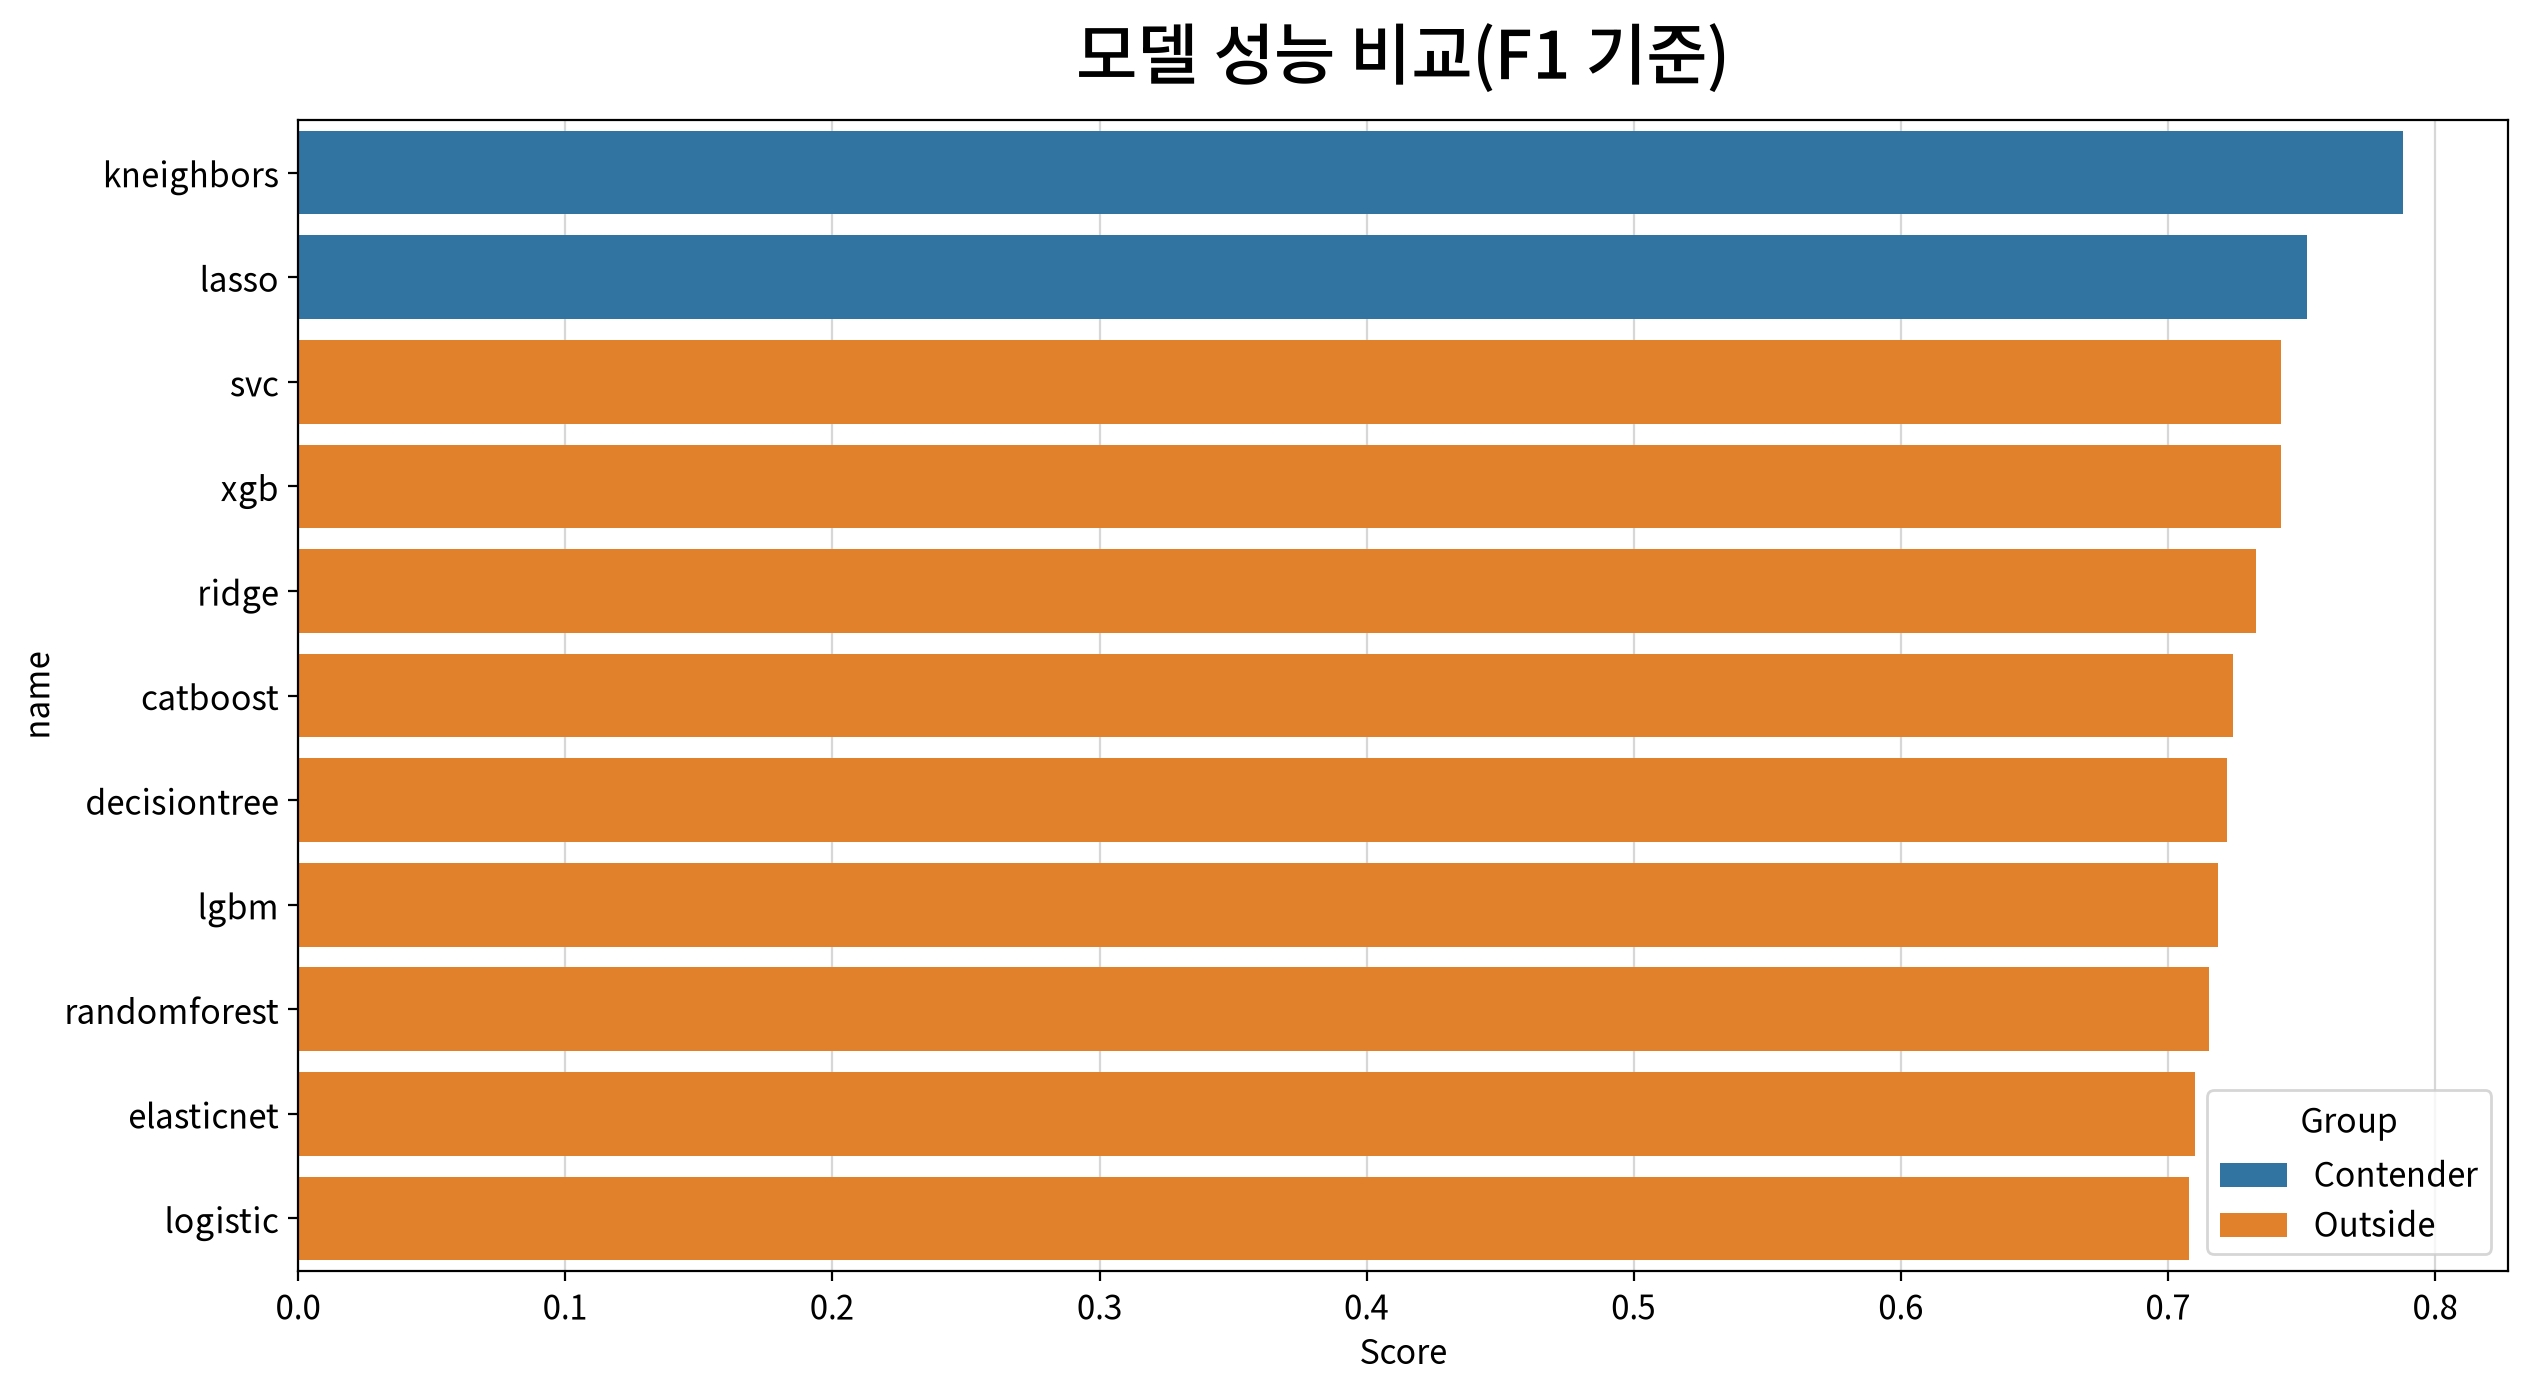

,Rank,Group,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,DOR,F1_Gap
name,,,,,,,,,,,
kneighbors,1,Contender,KNeighborsClassifier,0.843575,0.825397,0.753623,0.787879,0.865349,0.804210,27.529412,0.000
lasso,2,Contender,LogisticRegression,0.815642,0.781250,0.724638,0.751880,0.833729,0.827450,18.045113,0.046
svc,3,Outside,SVC,0.810056,0.777778,0.710145,0.742424,0.832016,0.826443,16.800000,0.058
xgb,4,Outside,XGBClassifier,0.810056,0.777778,0.710145,0.742424,0.836891,0.811141,16.800000,0.058
ridge,5,Outside,RidgeClassifier,0.804469,0.774194,0.695652,0.732824,0.831489,0.822862,15.673469,0.070
catboost,6,Outside,CatBoostClassifier,0.804469,0.793103,0.666667,0.724409,0.843478,0.836824,16.333333,0.081
decisiontree,7,Outside,DecisionTreeClassifier,0.776536,0.693333,0.753623,0.722222,0.776416,0.623081,11.570332,0.083
lgbm,8,Outside,LGBMClassifier,0.798883,0.779661,0.666667,0.718750,0.856258,0.828469,14.923077,0.088
randomforest,9,Outside,RandomForestClassifier,0.782123,0.720588,0.710145,0.715328,0.851515,0.795064,11.734211,0.092


['kneighbors', 'lasso']


In [18]:
rank_df = my_ml.cls_compare_models(models,    # 모델 객체들을 담은 딕셔너리
                                   x_test,    # 검증 데이터의 독립 변수
                                   y_test,    # 검증 데이터의 종속 변수
                                   primary="F1",                 # 주 지표
                                   aux=["ROC_AUC", "Accuracy"])  # 보조 지표

display(rank_df)    # 이전에는 마지막 줄의 반환값이 자동으로 표시됐으므로 직접 출력

# 근소 격차 그룹에 속한 모델만 #12에서 튜닝한다
contenders = rank_df[rank_df["Group"] == "Contender"].index.tolist()
print(contenders)

#### 💡 인사이트

| 순위 | 모델 | F1 | Accuracy | ROC_AUC | F1 격차(1위 대비) | 구분 |
|---|---|---|---|---|---|---|
| 1 | `kneighbors` | 0.788 | 0.844 | 0.865 | 0.000 | 근소 격차 그룹 |
| 2 | `lasso` | 0.752 | 0.816 | 0.834 | 0.046 | 근소 격차 그룹 |
| 3 | `svc` | 0.742 | 0.810 | 0.832 | 0.058 | 그룹 외 |
| 4 | `xgb` | 0.742 | 0.810 | 0.837 | 0.058 | 그룹 외 |
| 5 | `ridge` | 0.733 | 0.804 | 0.831 | 0.070 | 그룹 외 |
| 6 | `catboost` | 0.724 | 0.804 | 0.843 | 0.081 | 그룹 외 |
| 7 | `decisiontree` | 0.722 | 0.777 | 0.776 | 0.083 | 그룹 외 |
| 8 | `lgbm` | 0.719 | 0.799 | 0.856 | 0.088 | 그룹 외 |
| 9 | `randomforest` | 0.715 | 0.782 | 0.852 | 0.092 | 그룹 외 |
| 10 | `elasticnet` | 0.710 | 0.777 | 0.821 | 0.099 | 그룹 외 |
| 11 | `logistic` | 0.708 | 0.788 | 0.834 | 0.102 | 그룹 외 |

**선정 규칙** : ① 주 지표 F1 정렬 → ② 1위 F1의 5% 이내(0.039)를 **근소 격차 그룹**으로 묶음 → ③ 그룹 안에서 보조 지표(ROC_AUC·Accuracy)가 1위보다 0.050 넘게 나쁜 **결정적 결함** 점검 → ④ 최종 순위

- **근소 격차 그룹은 2개**(`kneighbors`, `lasso`)이고 결정적 결함은 없었다. 따라서 **1위는 `kneighbors`** 이며, #12에서는 이 2개만 튜닝한다.
- **KNN은 F1·Accuracy·ROC_AUC 세 지표 모두 1위**다. #10-3에서 정한 평가지표 우선순위(정확도 1순위)로 봐도 결론이 같다.
- **1위와 2위의 차이는 크지 않다.** KNN과 Lasso는 F1이 0.788 vs 0.752, 정답 수가 151명 vs 146명으로 **5명 차이**다. 검증 데이터가 179명이라 분할이 달라지면 좁혀질 수 있다.
- ⚠️ **그룹의 경계가 아슬아슬하다.**
  - Lasso는 F1 격차가 0.046로 한도(0.05)에 간신히 들어왔다.
  - 반대로 `SVC`·`XGBoost`는 격차 0.058로 탈락했지만, F1(0.742)이 컷오프(0.748)보다 0.006 낮을 뿐이다. 생존자 1명만 더 맞혔어도 그룹에 들어왔을 거리다.
  - 5%라는 기준 자체가 정해 둔 약속이므로 따르되, **튜닝 대상이 검증 데이터 1회 분할로 정해졌다**는 한계가 있다.
- **11개 모델 모두 정확도 바닥값 61.6%를 넘는다.** 가장 낮은 `Decision Tree`·`ElasticNet`(0.777)도 16.0%p 높다.
- ⚠️ **모델 비교와 선정이 모두 같은 179명 검증 데이터로 이뤄졌다.** 선정에 검증 데이터를 썼으므로 최종 성능은 낙관적일 수 있다. 교차검증 등으로 확인이 필요하다.

---
### 11-14. 이 장의 결론과 다음 단계

**핵심 인사이트**

1. **기본 설정에서 1위는 KNN**(F1 0.788, Accuracy 0.844, ROC_AUC 0.865)이고, 2위는 Lasso(F1 0.752)다. 가장 단순한 두 모형(거리 기반·L1 로지스틱)이 SVC와 앙상블 4종보다 높다. 복잡한 모형이 항상 낫지 않다.
2. **상위 2개와 나머지의 간격이 가장 크다.** 3위 이하는 F1이 0.742 이하로 이어지고, 그 사이 순위는 1~3명 차이로 갈린다.
3. **대부분의 모델이 생존자를 놓치는 쪽으로 기운다.** 11개 중 9개가 정밀도 > 재현율이며, 재현율은 0.667~0.754라서 **실제 생존자의 24.6~33.3%를 놓친다.**
4. **깊이 제한이 없는 Decision Tree는 과적합이 의심된다.** ROC_AUC 0.776로 11개 중 최하위다.
5. **검증 데이터 179명의 한계가 크다.** 1위와 2위의 차이도 5명이므로 교차검증으로 보완해야 한다.

**다음 단계 (#12. 하이퍼파라미터 튜닝)**

- 근소 격차 그룹 **2개(`kneighbors`, `lasso`)만** `GridSearchCV`(5-fold, `scoring="f1"`)로 튜닝하고, 기본 설정과 **같은 검증 데이터**로 비교한다.
- 그룹 밖 모델은 튜닝하지 않으므로, 최종 비교는 "튜닝한 2개 vs 기본 설정 그대로인 나머지"라는 한계를 가진다.

---
## #12. 하이퍼파라미터 튜닝

### 12-1. 튜닝 준비작업
#### 학습을 완료한 모델이 저장될 폴더

In [19]:
baseline_dir = f"titanic/baseline"  # 베이스라인 모델이 저장되어 있는 경로

if not os.path.exists(baseline_dir):
    os.makedirs(baseline_dir)

tune_dir = f"titanic/tune"          # 하이퍼파라미터 튜닝 모델이 저장될 경로

if not os.path.exists(tune_dir):
    os.makedirs(tune_dir)

> ✔️ 11-13에서 선정된 **근소 격차 그룹(Contender)** 2개 — `kneighbors`, `lasso` — 만 튜닝한다.

In [20]:
print(contenders)   # ['kneighbors', 'lasso']

['kneighbors', 'lasso']


### 12-2. KNN

In [21]:
%%time

# [실제 탐색용] 24개 조합
# param_grid = {
#     "model__n_neighbors": [3, 5, 10, 20, 30, 50],
#     "model__weights": ["uniform", "distance"],
#     "model__p": [1, 2]
# }
# [수업용] 8개 조합. 이웃 수가 적으면 과대적합, 많으면 과소적합 쪽으로 기운다.
param_grid = {
    "model__n_neighbors": [5, 10, 20, 30],       # 참조할 이웃 수
    "model__weights": ["uniform", "distance"]    # 거리에 따른 가중 방식
}

model = my_ml.load_model(f"{baseline_dir}/kneighbors.pkl")   # 베이스모델 로드

# 파라미터 탐색을 위한 그리드 서치 객체 생성
gs = GridSearchCV(estimator=model, param_grid=param_grid, cv=5, scoring="f1", n_jobs=-1)
gs.fit(x_train, y_train)                                # 파라미터 탐색 수행
gs.name_ = f"{model.name_}_tuned"                       # 튜닝 완료 객체에 이름 부여
my_ml.save_model(gs, f"{tune_dir}/kneighbors.pkl")      # 튜닝된 모델 저장
display(my_ml.cls_score(gs, x_test, y_test))            # 성능 평가 결과 출력
display(gs)                                             # 학습 모형 구조 출력

,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,DOR
Model,,,,,,,
KNeighborsClassifier,0.843575,0.825397,0.753623,0.787879,0.865349,0.80421,27.529412


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...(n_jobs=-1))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__n_neighbors': [5, 10, ...], 'model__weights': ['uniform', 'distance']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbos

CPU times: total: 844 ms
Wall time: 13.6 s


### 12-3. Lasso

In [22]:
%%time

# [실제 탐색용] 15개 조합
# param_grid = {
#     "model__C": [0.001, 0.01, 0.1, 1.0, 10.0],
#     "model__solver": ["liblinear"]
# }
# [수업용] 8개 조합.
param_grid = {
    "model__C": [0.01, 0.1, 1.0, 10.0],       # 규제 강도의 역수 (L1)
    "model__solver": ["liblinear"]            # L1 을 지원하는 최적화 알고리즘
}

model = my_ml.load_model(f"{baseline_dir}/lasso.pkl")   # 베이스모델 로드

# 파라미터 탐색을 위한 그리드 서치 객체 생성
gs = GridSearchCV(estimator=model, param_grid=param_grid, cv=5, scoring="f1", n_jobs=-1)
gs.fit(x_train, y_train)                            # 파라미터 탐색 수행
gs.name_ = f"{model.name_}_tuned"                   # 튜닝 완료 객체에 이름 부여
my_ml.save_model(gs, f"{tune_dir}/lasso.pkl")       # 튜닝된 모델 저장
display(my_ml.cls_score(gs, x_test, y_test))        # 성능 평가 결과 출력
display(gs)                                         # 학습 모형 구조 출력

,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,DOR
Model,,,,,,,
LogisticRegression,0.815642,0.78125,0.724638,0.75188,0.833729,0.82745,18.045113


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...liblinear'))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'model__C': [0.01, 0.1, ...], 'model__solver': ['liblinear']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of informatio

CPU times: total: 438 ms
Wall time: 688 ms


#### 💡 인사이트 (튜닝 대상 2종)

| 모델 | F1 (기본 → 튜닝) | Accuracy (기본 → 튜닝) | ROC_AUC (기본 → 튜닝) | 판정 |
|---|---|---|---|---|
| `KNN` | 0.788 → 0.788 | 0.844 → 0.844 | 0.865 → 0.865 | ⏸ 변화 없음 |
| `Lasso (L1 로지스틱)` | 0.752 → 0.752 | 0.816 → 0.816 | 0.834 → 0.834 | ⏸ 변화 없음 |

- **두 모델 모두 튜닝 전후의 7개 지표(Accuracy~DOR)가 소수 여섯째 자리까지 같다.** 예측이 달라지지 않았다는 뜻이므로, 탐색 범위 안에서 **기본 설정과 같은 모형이 선택**된 것으로 보인다. (선택된 파라미터는 출력되지 않아 확정은 아니다)
- **KNN : 기본값 5명은 탐색 범위(5·10·20·30)의 가장 작은 값이다.**
  - 이웃을 늘려도(10·20·30명) 5-fold CV 기준으로 나아지지 않았다는 것은 확인됐다.
  - 하지만 최적값이 탐색 범위의 **경계**에 있으므로, 5보다 작은 값(예: 3)을 포함하면 결과가 달라질 수 있다. 탐색 범위의 한계다.
- **Lasso : 기본값 C = 1.0은 탐색 범위(0.01·0.1·1.0·10)의 안쪽 값이다.** 결과가 기본 설정과 같으므로 C = 1.0이 선택됐을 가능성이 높고, 그렇다면 범위의 양 끝보다 중간이 낫다는 뜻이다. (`best_params_` 미출력으로 확정은 아니다)
- **튜닝으로 얻은 개선은 없다.** 근소 격차 그룹 2개가 이미 기본 설정에서 충분히 좋았거나, 탐색 범위가 기본값 주변에 한정되었다.

### 12-4. 최고 성능 모델 선정
#### (1) 튜닝 파일 목록

In [23]:
# 작업폴더 내의 모든 pkl 파일 목록 확인
model_pickles = gl.glob(f"{tune_dir}/*.pkl")
print(model_pickles)

['titanic/tune\\kneighbors.pkl', 'titanic/tune\\lasso.pkl']


#### (2) 튜닝 모델 불러오기

In [24]:
models = {}                         # 모델명과 모델 객체를 저장할 딕셔너리

for p in model_pickles:
    model = my_ml.load_model(p)     # 모델 로드
    models[model.name_] = model     # 모델명과 모델 객체를 딕셔너리에 저장

# 로드된 모델과 모델 객체의 타입 출력
for name, model in models.items():
    print(f"- {name}: {type(model)}")

- kneighbors_tuned: <class 'sklearn.model_selection._search.GridSearchCV'>
- lasso_tuned: <class 'sklearn.model_selection._search.GridSearchCV'>


#### (3) 모델 간 성능 평가 비교


◆ Score Table Ranking : primary=F1, aux=['ROC_AUC', 'Accuracy']

▲ step1: 주 지표(F1) 기준 정렬 — 높을수록 좋음
    1. kneighbors_tuned F1    =            0.788
    2. lasso_tuned    F1    =            0.752

▲ step2: 근소 격차 그룹 묶기 (1등의 5% 이내)
   - 1등 F1     : 0.788
   - 허용 격차    : 1등보다 0.039 까지
   - 근소 격차 그룹 (2) : ['kneighbors_tuned', 'lasso_tuned']
   - 그룹 외부     (0) : []

▲ step3: 보조 지표 결정적 결함 점검 (근소 격차 그룹 내부)
       · ROC_AUC best=     0.865   결함조건: 1등보다 0.050 넘게 나쁘면
       · Accuracy best=     0.844   결함조건: 1등보다 0.050 넘게 나쁘면
       · kneighbors_tuned 0개 (결함 없음)
       · lasso_tuned    0개 (결함 없음)

▲ step4: 최종 Rank
    1. kneighbors_tuned [그룹 내]
    2. lasso_tuned    [그룹 내]



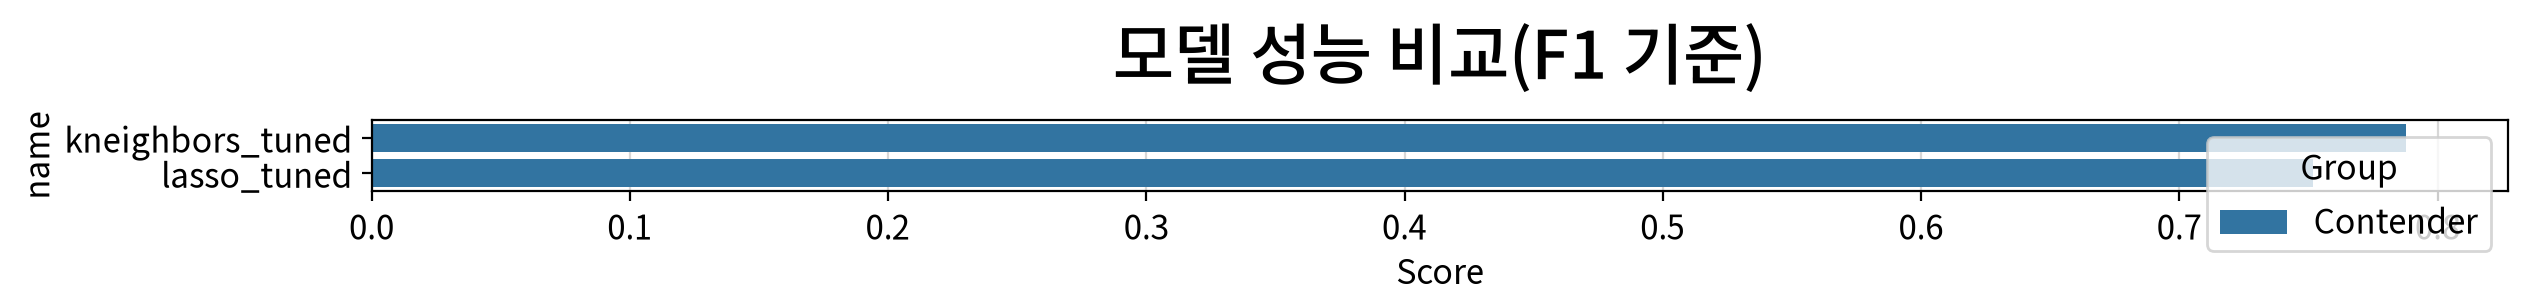

,Rank,Group,Model,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC,DOR,F1_Gap
name,,,,,,,,,,,
kneighbors_tuned,1,Contender,KNeighborsClassifier,0.843575,0.825397,0.753623,0.787879,0.865349,0.80421,27.529412,0.000
lasso_tuned,2,Contender,LogisticRegression,0.815642,0.781250,0.724638,0.751880,0.833729,0.82745,18.045113,0.046


In [25]:
my_ml.cls_compare_models(models,                       # 모델 객체들을 담은 딕셔너리
                         x_test,                       # 검증 데이터의 독립 변수
                         y_test,                       # 검증 데이터의 종속 변수
                         primary="F1",                 # 주 지표
                         aux=["ROC_AUC", "Accuracy"])  # 보조 지표

#### 💡 인사이트

| 순위 | 모델 | F1 | Accuracy | ROC_AUC | 정답 수 |
|---|---|---|---|---|---|
| 1 | `kneighbors_tuned` | 0.788 | 0.844 | 0.865 | 151명 |
| 2 | `lasso_tuned` | 0.752 | 0.816 | 0.834 | 146명 |

- **비교 대상이 2개뿐이라 근소 격차 그룹 판정은 의미가 없다.** 출력의 "그룹 내 2개 / 그룹 외 0개"는 모두 이미 그룹에 속한 모델만 남았기 때문이며, 순위는 F1 순서 그대로다.
- **1위는 `kneighbors_tuned`** 다. F1·Accuracy·ROC_AUC 모두 Lasso보다 높고, 11-13의 기본 설정 순위(1위 KNN, 2위 Lasso)와 같다.
- **격차는 F1 0.036, 정답 5명이다.** ROC_AUC는 0.865 vs 0.834로 0.032 차이다. 반대로 PR_AUC는 Lasso가 더 높다(0.827 vs 0.804).
  - 지표에 따라 우위가 갈리므로 **KNN이 모든 면에서 앞선다고 말하기는 어렵다.**

---
### 12-5. 이 장의 결론과 다음 단계

**핵심 인사이트**

1. **튜닝 후에도 1위는 KNN**(F1 0.788, Accuracy 0.844)이고 2위는 Lasso(F1 0.752)다. **두 모델 모두 튜닝 전후 결과가 같았다.** 탐색 범위 안에서는 기본 설정이 이미 최선이었다는 뜻이다.
2. **KNN의 탐색 범위는 한쪽이 막혀 있다.** 기본값 이웃 수 5명이 범위의 최솟값이라 5보다 작은 값을 확인하지 못했다. "KNN은 튜닝해도 변하지 않는다"고 결론짓기 전에 범위를 넓혀 확인해야 한다.
3. **1위와 2위의 차이는 정답 5명**이고 PR_AUC는 Lasso가 더 높다. 검증 데이터 1회 분할만으로 최종 모델을 확정하기는 이르다.
4. **튜닝은 근소 격차 그룹 2개에만 했다.** 경계 밖에서 1명 차이로 탈락한 `SVC`·`XGBoost` 등은 기본 설정 그대로이므로, 튜닝했다면 순위가 달라졌을 가능성을 배제할 수 없다.

**다음 단계**

- **과적합 진단** : `KNN`과 `Lasso`(필요하면 `Decision Tree`)의 **훈련 성능 vs 검증 성능**과 **5-fold CV 점수**를 비교한다.
  - KNN은 훈련 데이터를 예측할 때 **자기 자신이 이웃에 포함**되어 훈련 점수가 부풀려지므로, 훈련/검증 비교보다 교차검증 점수 비교가 더 믿을 만하다.
- **SHAP 분석** : 최종 모델을 정한 뒤 변수별 기여도를 해석한다. Lasso면 로지스틱 계수(오즈비)와 같은 결론인지 비교하고, KNN이면 `KernelExplainer`를 써야 해 계산이 느리다.
- **기록 보완** : `GridSearchCV`의 `best_params_`와 `best_score_`가 출력되지 않아 선택된 조합을 확인할 수 없다. 다음 단계에서 함께 출력한다.